In [3]:
"""
Data Source: https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics
"""

'\nData Source: https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics\n'

In [ ]:
import pandas as pd
import matplotlib
from datetime import date
import matplotlib.pyplot as plt


In [5]:
df = pd.read_csv('ecommerce_sales_customer_analytics_150k.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country          138116 non-null  str    
 14 

In [6]:
df.describe(include='all')

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
count,138116,138116,138116,138116,138116,138116,138116,138116.000000,138116,138116,...,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116,138116.000000
unique,138116,1826,68991,4,4,24911,21564,NaN,3,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
top,ORD-301242,2025-12-30,14:55:55,Completed,Mobile App,CUST-014687,John Smith,NaN,Female,Consumer,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN
freq,1,143,11,113559,55318,19,97,NaN,66439,75636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,137782,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.862681,NaN,NaN,...,237.621614,122.462933,22.278080,1282.503575,708.903449,551.322046,45.065997,8971.639047,NaN,6.990559
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.467676,NaN,NaN,...,378.779459,140.939368,16.022739,1169.274669,730.044970,516.300936,13.120357,4430.506588,NaN,2.444166
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.000000,NaN,NaN,...,0.000000,0.340000,0.000000,5.800000,1.970000,-1281.590000,-59.550000,22.550000,NaN,1.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.000000,NaN,NaN,...,26.327500,34.650000,9.820000,448.200000,207.667500,190.757500,38.880000,5713.570000,NaN,5.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.000000,NaN,NaN,...,103.285000,77.010000,19.190000,950.760000,478.955000,408.395000,46.990000,8392.525000,NaN,7.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.000000,NaN,NaN,...,277.125000,156.200000,30.750000,1744.582500,953.762500,752.845000,53.770000,11651.030000,NaN,9.000000


# CLEANING

In [7]:
df.columns

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_name', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region', 'customer_postal_code', 'payment_method',
       'payment_status', 'currency', 'shipping_method', 'warehouse',
       'delivery_days', 'estimated_delivery_days', 'delivery_status',
       'return_status', 'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity',
       'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
       'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
       'customer_lifetime_value', 'is_repeat_customer',
       'customer_order_count'],
      dtype='str')

In [8]:
# relevant data
df[['order_id', 'order_date', 'order_time', 'order_status',    
       'customer_segment', 'customer_type', 'customer_country', 'region',
       'payment_status', 'currency', 'shipping_method', 'delivery_days', 
       'estimated_delivery_days', 'delivery_status', 'return_status', 
       'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
       'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
       'customer_lifetime_value', 'is_repeat_customer','customer_order_count']]

,order_id,order_date,order_time,order_status,customer_segment,customer_type,customer_country,region,payment_status,currency,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Consumer,Loyal,USA,South,Paid,USD,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Premium,Loyal,Germany,South,Pending,EUR,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Premium,Loyal,USA,East,Paid,USD,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Consumer,Loyal,USA,South,Paid,USD,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Consumer,Loyal,India,West,Paid,INR,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138111,ORD-481534,2025-09-27,13:00:50,Completed,Consumer,Loyal,USA,East,Paid,USD,...,8.84,14.28,6.15,224.42,101.77,116.50,51.91,18182.63,True,14
138112,ORD-487614,2023-07-22,09:13:25,Returned,Premium,Loyal,USA,West,Refunded,USD,...,0.00,147.30,9.18,2260.80,1246.73,1004.89,44.45,10004.74,True,10
138113,ORD-248062,2025-09-08,18:30:32,Cancelled,Consumer,Loyal,UK,North,Failed,GBP,...,0.00,372.37,26.94,2261.16,970.95,1263.27,55.87,16442.68,True,15
138114,ORD-252033,2022-04-06,14:50:07,Completed,Consumer,Loyal,USA,Central,Paid,USD,...,174.60,130.58,84.39,2080.38,1042.40,953.59,45.84,8047.00,True,5


In [9]:
# to date datatype
df['order_date'] = pd.to_datetime(df['order_date'])

In [10]:
# unifying currency to USD
moneyCols = ['gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
    'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
    'customer_lifetime_value']
df[['currency'] + moneyCols]

,currency,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value
0,USD,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68
1,EUR,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48
2,USD,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44
3,USD,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30
4,INR,2474.52,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10
...,...,...,...,...,...,...,...,...,...,...
138111,USD,212.83,8.84,14.28,6.15,224.42,101.77,116.50,51.91,18182.63
138112,USD,2104.32,0.00,147.30,9.18,2260.80,1246.73,1004.89,44.45,10004.74
138113,GBP,1861.85,0.00,372.37,26.94,2261.16,970.95,1263.27,55.87,16442.68
138114,USD,2040.01,174.60,130.58,84.39,2080.38,1042.40,953.59,45.84,8047.00


In [11]:
# display all currency in the dataset
df['currency'].unique()

<StringArray>
['USD', 'EUR', 'INR', 'CAD', 'GBP', 'AUD', 'AED']
Length: 7, dtype: str

In [12]:
from Converter import CurrencyConverter
c = CurrencyConverter()

In [13]:
firstDate = df['order_date'].min().strftime("%Y-%m-%d")
firstDate

'2021-01-01'

In [14]:
#c.request_range_rates(firstDate)

In [15]:
c.convert(100,"GBP")

133.50956596040106

In [16]:
def DFtoUSD(df: pd.DataFrame, cols: list):
    """
    take the data frame and change the selected columns into USD using the currency dict
    """
    for col in cols:
        df[f"{col}_USD"] = df.apply(lambda x: c.convert(value = x[col], quote=x['currency']), axis=1)
        df[f"{col}_USD"] = df[f"{col}_USD"].round(2)
    return df


In [17]:
DFtoUSD(df,moneyCols)

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,customer_order_count,gross_sales_USD,discount_amount_USD,tax_amount_USD,shipping_cost_USD,net_sales_USD,product_cost_USD,profit_USD,profit_margin_percentage_USD,customer_lifetime_value_USD
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,11,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,11,3518.08,1628.98,358.93,10.07,2258.11,2273.18,-25.14,-1.24,14580.16
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,6,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,7,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,8,26.02,1.41,4.43,0.24,29.28,12.95,16.09,0.58,139.21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138111,ORD-481534,2025-09-27,13:00:50,Completed,Mobile App,CUST-007151,Donna Ruiz,41,Female,Consumer,...,14,212.83,8.84,14.28,6.15,224.42,101.77,116.50,51.91,18182.63
138112,ORD-487614,2023-07-22,09:13:25,Returned,Social Media,CUST-006686,Jeremy Aguirre,40,Male,Premium,...,10,2104.32,0.00,147.30,9.18,2260.80,1246.73,1004.89,44.45,10004.74
138113,ORD-248062,2025-09-08,18:30:32,Cancelled,Mobile App,CUST-017497,Timothy Williams,39,Female,Consumer,...,15,2485.75,0.00,497.15,35.97,3018.86,1296.31,1686.59,74.59,21952.55
138114,ORD-252033,2022-04-06,14:50:07,Completed,Social Media,CUST-005723,Charles Hanson,46,Female,Consumer,...,5,2040.01,174.60,130.58,84.39,2080.38,1042.40,953.59,45.84,8047.00


In [18]:
df[['order_date','currency','gross_sales','gross_sales_USD']]

,order_date,currency,gross_sales,gross_sales_USD
0,2023-11-06,USD,1350.19,1350.19
1,2025-12-24,EUR,3144.64,3518.08
2,2021-07-05,USD,522.81,522.81
3,2023-01-21,USD,544.62,544.62
4,2022-05-13,INR,2474.52,26.02
...,...,...,...,...
138111,2025-09-27,USD,212.83,212.83
138112,2023-07-22,USD,2104.32,2104.32
138113,2025-09-08,GBP,1861.85,2485.75
138114,2022-04-06,USD,2040.01,2040.01


In [19]:
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', None):
    print(df.describe(include='all'))

          order_id                  order_date order_time order_status  \
count       138116                      138116     138116       138116   
unique      138116                         NaN      68991            4   
top     ORD-301242                         NaN   14:55:55    Completed   
freq             1                         NaN         11       113559   
mean           NaN  2023-07-21 10:11:31.662081        NaN          NaN   
min            NaN         2021-01-01 00:00:00        NaN          NaN   
25%            NaN         2022-04-20 00:00:00        NaN          NaN   
50%            NaN         2023-08-01 00:00:00        NaN          NaN   
75%            NaN         2024-10-29 00:00:00        NaN          NaN   
max            NaN         2025-12-31 00:00:00        NaN          NaN   
std            NaN                         NaN        NaN          NaN   

       sales_channel  customer_id customer_name   customer_age  gender  \
count         138116       138116    

In [ ]:
def seasonal_index(df ,threshold = 1.2):
    """
    calculation: Seasonal Index = week sales ÷ Average week sales in that year
    """
    df["year"] = df['order_date'].dt.isocalendar().year
    df["week"] = df["order_date"].dt.isocalendar().week
    # weekly sales per year
    sales = (df.groupby(["customer_country","year", "week"], as_index=False)
            ["net_sales_USD"].sum())
    sales.rename(columns={'net_sales_USD':'week_sales'},inplace=True)
    # calculate the average weekly sales for each year then return the weeks over threshold
    sales['avg_week_sales'] = sales.groupby(["customer_country","year"])["week_sales"].transform('mean')
    sales['season_index'] = sales['week_sales'] / sales['avg_week_sales']

        

    return sales.loc[sales['season_index'] > threshold]

idx = seasonal_index(df,threshold=0)

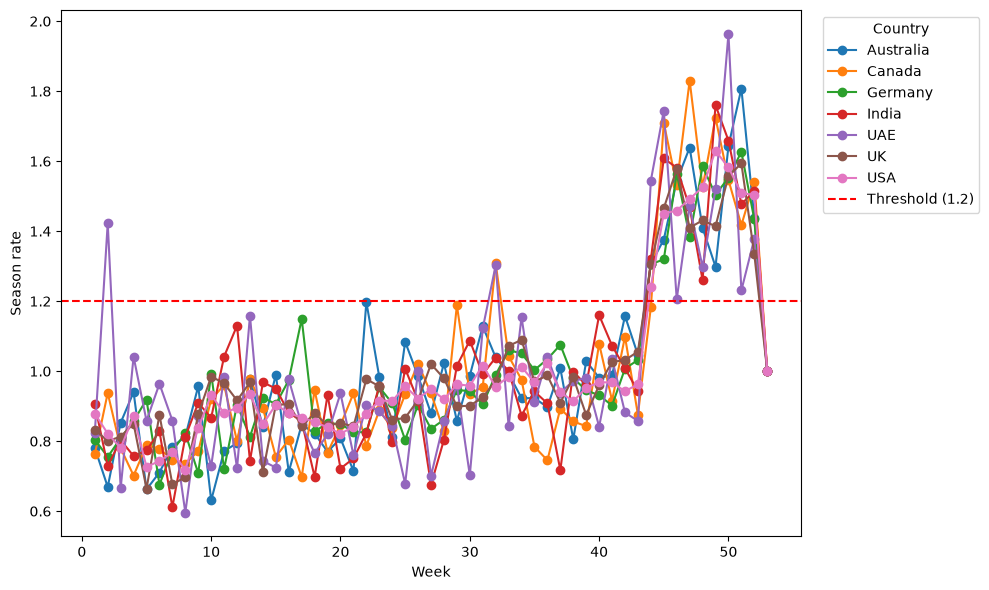

In [43]:
pivot = idx.pivot_table(
    index="week", columns="customer_country", values="season_index", aggfunc="mean")

ax = pivot.plot(figsize=(10, 6), marker="o")
ax.axhline(y=1.2, color="red", linestyle="--", linewidth=1.5, label="Threshold (1.2)")

ax.set_xlabel("Week")
ax.set_ylabel("Season rate")
ax.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

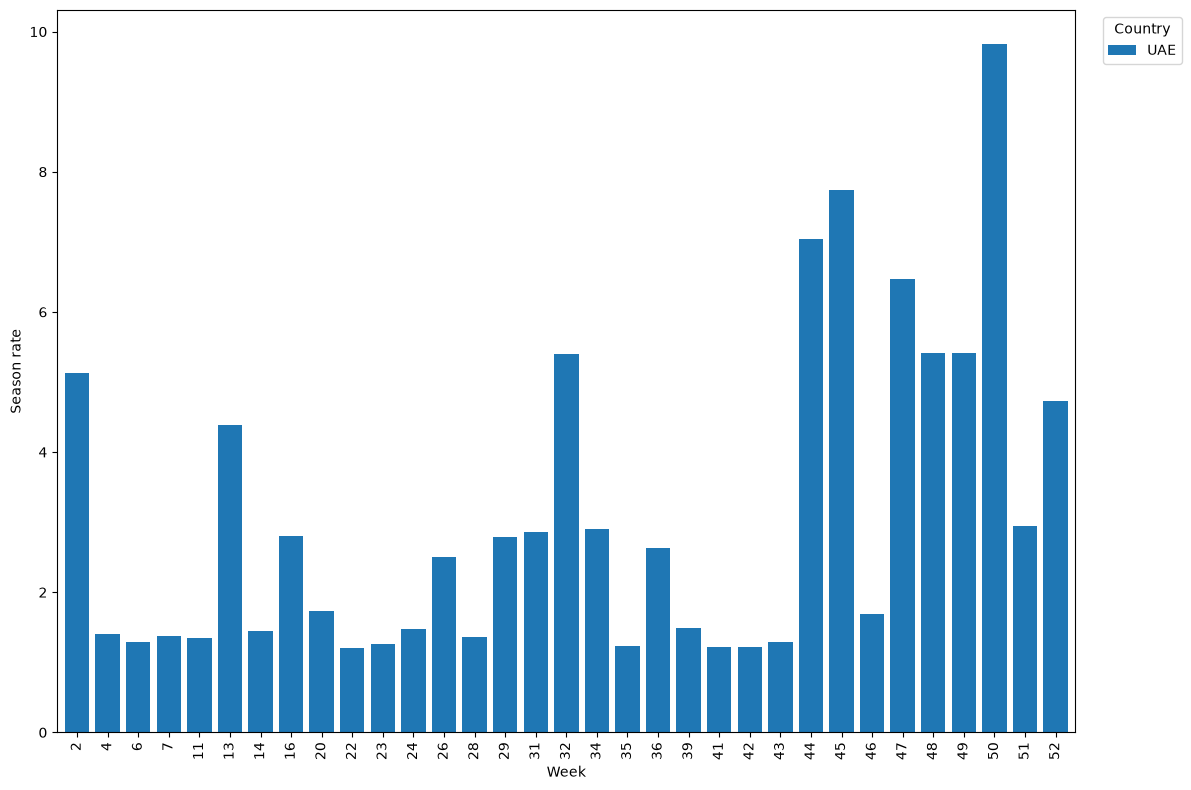

In [49]:
peak_weeks_per_country = seasonal_index(df, threshold=1.2)
peak_weeks_per_country[peak_weeks_per_country['customer_country'] == 'UAE']
pivot = peak_weeks_per_country[peak_weeks_per_country['customer_country'] == 'UAE'].pivot_table(
    index="week", columns="customer_country", values="season_index", aggfunc="sum")

ax = pivot.plot(kind='bar',figsize=(12, 8),width=0.8)
ax.set_xlabel("Week")
ax.set_ylabel("Season rate")
ax.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
